# Paso 1 — Limpieza y filtrado automático del dataset PISA

**Objetivo:** Reducir las ~4942 columnas del dataset combinado (estudiante + escuela + docente) a un subconjunto manejable de variables categóricas/ordinales aptas para EFA, IRT y LCA.

**Filtros aplicados en orden:**
1. Eliminar columnas con demasiados valores perdidos (>40%)
2. Eliminar identificadores, pesos muestrales y variables derivadas de PISA
3. Eliminar variables de texto libre
4. Separar numéricas continuas de categóricas/ordinales
5. Eliminar variables con varianza casi cero
6. Eliminar variables numéricas continuas (no aptas para EFA/IRT/LCA)
7. Reporte final y guardado

**Output:** `dataset_filtrado.csv` listo para el Paso 2 (EFA por bloques)

## 0. Configuración

In [226]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ── AJUSTA ESTOS DOS VALORES ──────────────────────────────────────────────────
# RUTA_CSV = "/workspace/data/ready/COLLECT_COMP_dataset_treated.csv"          # ruta a tu archivo CSV tratado
RUTA_CSV = "/workspace/data/2018/collection_csv_peru/merge/PISA_PERU_MASTER.csv"          # ruta a tu archivo CSV sin tratar
RUTA_OUTPUT = "/workspace/data/output/2018/national"
SEPARADOR = ","                       # cambia a ";" si tu CSV usa punto y coma
ENCODING  = "utf-8"                   # prueba "latin-1" si hay errores de lectura
# ─────────────────────────────────────────────────────────────────────────────

# Umbrales de filtrado (puedes ajustar)
UMBRAL_MISSING      = 0.40   # elimina columnas con >40% de NaN
UMBRAL_VARIANZA_0   = 0.95   # elimina columnas donde una categoría ocupa >95% de los datos
MAX_CATEGORIAS_ORD  = 10     # columnas numéricas con <=10 valores únicos se tratan como ordinales

plt.rcParams["figure.dpi"] = 110
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 1. Carga del dataset

In [227]:
df_raw = pd.read_csv(RUTA_CSV, sep=SEPARADOR, encoding=ENCODING, low_memory=False)

print(f"Filas    : {df_raw.shape[0]:,}")
print(f"Columnas : {df_raw.shape[1]:,}")
print()
print("Primeras columnas:")
print(df_raw.columns[:20].tolist())

Filas    : 6,086
Columnas : 6,107

Primeras columnas:
['CNTRYID', 'CNT', 'CNTSCHID', 'CNTSTUID', 'CYC', 'NatCen', 'Region', 'STRATUM', 'SUBNATIO', 'OECD', 'ADMINMODE', 'LANGTEST_QQQ', 'LANGTEST_COG', 'LANGTEST_PAQ', 'BOOKID_stu_all', 'RDESIGN', 'RCORE_TEST', 'RS1_TEST', 'RS1_LEV', 'RS2_TEST']


In [228]:
# Vista rápida de tipos de datos
tipo_counts = df_raw.dtypes.value_counts()
print("Tipos de columnas:")
print(tipo_counts)

Tipos de columnas:
float64    6087
int64        14
str           6
Name: count, dtype: int64


## 2. Filtro 1 — Eliminar columnas con demasiados valores perdidos

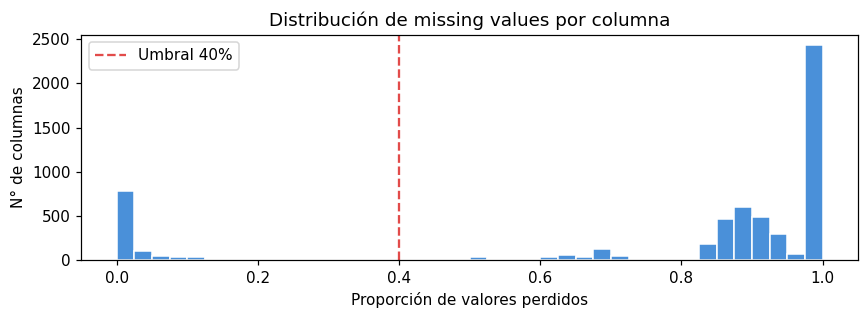

Columnas eliminadas por missing >40%: 4979
Columnas restantes: 1,128


In [229]:
missing_ratio = df_raw.isnull().mean()

# Histograma de missing por columna
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(missing_ratio, bins=40, color="#4A90D9", edgecolor="white")
ax.axvline(UMBRAL_MISSING, color="#E24B4A", linewidth=1.5, linestyle="--",
           label=f"Umbral {UMBRAL_MISSING*100:.0f}%")
ax.set_xlabel("Proporción de valores perdidos")
ax.set_ylabel("N° de columnas")
ax.set_title("Distribución de missing values por columna")
ax.legend()
plt.tight_layout()
plt.show()

cols_alta_missing = missing_ratio[missing_ratio > UMBRAL_MISSING].index.tolist()
print(f"Columnas eliminadas por missing >{UMBRAL_MISSING*100:.0f}%: {len(cols_alta_missing)}")

df = df_raw.drop(columns=cols_alta_missing)
print(f"Columnas restantes: {df.shape[1]:,}")

## 3. Filtro 2 — Eliminar identificadores, pesos y variables derivadas de PISA

PISA tiene convenciones de nombres muy específicas. Eliminamos por prefijo/sufijo conocido.

In [230]:
# Patrones de columnas que PISA genera automáticamente y NO son ítems originales
PREFIJOS_EXCLUIR = [
    "PV",        # Plausible Values (PV1MATH, PV2READ, etc.) — ya son scores derivados
    "W_FST",     # Pesos muestrales de estudiantes
    "W_SCH",     # Pesos muestrales de escuelas
    "W_TCH",     # Pesos muestrales de docentes
    "WVARSTRR",  # Varianza de pesos
]

SUFIJOS_EXCLUIR = [
    "_FLAG",     # flags de calidad de dato
]

# Nombres exactos de columnas de identificación
IDS_EXACTOS = [
    "CNTRYID", "CNT", "CNTSCHID", "CNTSTUID",
    "SCHOOLID", "STUIDINSCH", "STUDID",
    "TCID", "TCIDSCH",                         # IDs de docentes
    "STRATUM", "SUBNATIO", "OECD",
    "ESCS",    # índice compuesto PISA — se puede agregar de vuelta luego como referencia
    "HISEI", "PARED", "HOMEPOS",               # componentes del ESCS
    "LANGTEST_QQQ", "LANGTEST_COG",
]

def es_columna_excluida(nombre):
    n = nombre.upper()
    if n in [x.upper() for x in IDS_EXACTOS]:
        return True
    for pref in PREFIJOS_EXCLUIR:
        if n.startswith(pref.upper()):
            return True
    for suf in SUFIJOS_EXCLUIR:
        if n.endswith(suf.upper()):
            return True
    return False

cols_pisa_derivadas = [c for c in df.columns if es_columna_excluida(c)]
print(f"Columnas eliminadas (IDs, pesos, PVs, índices derivados): {len(cols_pisa_derivadas)}")
print("Ejemplos:", cols_pisa_derivadas[:15])

# Guardar los PVs aparte — los usaremos luego como variable de referencia de rendimiento
cols_pv = [c for c in df_raw.columns if c.upper().startswith("PV")]
df_pv = df_raw[cols_pv].copy()
print(f"\nPlausible Values guardados aparte para referencia: {len(cols_pv)} columnas")
print("Ejemplos PVs:", cols_pv[:10])

df = df.drop(columns=cols_pisa_derivadas, errors="ignore")
print(f"\nColumnas restantes: {df.shape[1]:,}")

Columnas eliminadas (IDs, pesos, PVs, índices derivados): 177
Ejemplos: ['CNTRYID', 'CNT', 'CNTSCHID', 'CNTSTUID', 'STRATUM', 'SUBNATIO', 'OECD', 'LANGTEST_QQQ', 'LANGTEST_COG', 'PARED', 'HISEI', 'ESCS', 'HOMEPOS', 'W_FSTUWT', 'W_FSTURWT1']

Plausible Values guardados aparte para referencia: 90 columnas
Ejemplos PVs: ['PV1MATH', 'PV2MATH', 'PV3MATH', 'PV4MATH', 'PV5MATH', 'PV6MATH', 'PV7MATH', 'PV8MATH', 'PV9MATH', 'PV10MATH']

Columnas restantes: 951


## 4. Filtro 3 — Eliminar columnas de texto libre

Columnas de tipo `object` con demasiados valores únicos son texto libre, no categóricas.

In [231]:
N_FILAS = len(df)

# Umbral: si una columna object tiene más del 20% de valores únicos respecto a las filas,
# es probablemente texto libre o un ID enmascarado
UMBRAL_TEXTO = 0.20

cols_texto = []
for col in df.select_dtypes(include="object").columns:
    n_unicos = df[col].nunique(dropna=True)
    if n_unicos / N_FILAS > UMBRAL_TEXTO:
        cols_texto.append(col)

print(f"Columnas de texto libre eliminadas: {len(cols_texto)}")
print("Ejemplos:", cols_texto[:10])

df = df.drop(columns=cols_texto)
print(f"Columnas restantes: {df.shape[1]:,}")

Columnas de texto libre eliminadas: 0
Ejemplos: []
Columnas restantes: 951


/tmp/ipykernel_21/4241287725.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


## 5. Filtro 4 — Separar numéricas continuas de categóricas/ordinales

Una columna numérica con pocos valores únicos (≤10) es ordinal y sirve para EFA/IRT/LCA.  
Una columna con muchos valores únicos es continua y **no** es apta para estos métodos.

In [232]:
cols_numericas = df.select_dtypes(include=[np.number]).columns.tolist()
cols_objeto    = df.select_dtypes(include="object").columns.tolist()

cols_continuas  = []
cols_ordinales  = []

for col in cols_numericas:
    n_unicos = df[col].nunique(dropna=True)
    if n_unicos <= MAX_CATEGORIAS_ORD:
        cols_ordinales.append(col)
    else:
        cols_continuas.append(col)

print(f"Columnas numéricas totales  : {len(cols_numericas)}")
print(f"  → Ordinales (≤{MAX_CATEGORIAS_ORD} únicos)  : {len(cols_ordinales)}  ← estas van al EFA")
print(f"  → Continuas (>{MAX_CATEGORIAS_ORD} únicos)  : {len(cols_continuas)}  ← se separan")
print(f"Columnas categóricas (object): {len(cols_objeto)}")

# Guardar las continuas aparte (pueden ser útiles para análisis descriptivo)
df_continuas = df[cols_continuas].copy()
print(f"\nEjemplos de continuas separadas: {cols_continuas[:10]}")

Columnas numéricas totales  : 947
  → Ordinales (≤10 únicos)  : 462  ← estas van al EFA
  → Continuas (>10 únicos)  : 485  ← se separan
Columnas categóricas (object): 4

Ejemplos de continuas separadas: ['BOOKID_stu_all', 'ST003D02T', 'ST016Q01NA', 'OCOD1', 'OCOD2', 'OCOD3', 'AGE', 'BMMJ1', 'BFMJ2', 'BSMJ']


/tmp/ipykernel_21/1294351045.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_objeto    = df.select_dtypes(include="object").columns.tolist()


Paso extra agregado

In [233]:
# El dataset de trabajo queda solo con ordinales + categóricas object
cols_para_analisis = cols_ordinales + cols_objeto
df = df[cols_para_analisis].copy()
print(f"Columnas para EFA/IRT/LCA hasta ahora: {df.shape[1]:,}")

Columnas para EFA/IRT/LCA hasta ahora: 466


In [234]:
# ── CORRECCIÓN: recuperar Likert con decimales desde df_continuas ─────────────
#
# Criterio: una columna float es Likert disfrazada si:
#   1. Todos sus valores no-NaN son enteros (x == int(x))
#   2. El número de valores únicos enteros es <= MAX_CATEGORIAS_ORD (10)
#
# Si cumple ambas condiciones → es ordinal → se convierte a int y se recupera.

cols_recuperadas = []
cols_continuas_reales = []

for col in df_continuas.columns:
    serie = df_continuas[col].dropna()
    if len(serie) == 0:
        continue

    # ¿Son todos los valores enteros disfrazados de float?
    es_entero = (serie == serie.astype(int)).all()

    if es_entero:
        n_unicos = serie.astype(int).nunique()
        if n_unicos <= MAX_CATEGORIAS_ORD:
            # Es Likert/ordinal — recuperar
            df[col] = df_continuas[col].apply(
                lambda x: int(x) if pd.notna(x) else np.nan
            )
            cols_recuperadas.append(col)
        else:
            cols_continuas_reales.append(col)
    else:
        # Tiene decimales reales (ej: 3.7, 12.4) → continua genuina
        cols_continuas_reales.append(col)

print(f"Columnas Likert recuperadas (float→int ordinal) : {len(cols_recuperadas)}")
print(f"Columnas continuas genuinas (se quedan fuera)   : {len(cols_continuas_reales)}")
print(f"\nTotal columnas para EFA/IRT/LCA ahora          : {df.shape[1]:,}")

# Actualizar df_continuas para que solo tenga las genuinamente continuas
df_continuas = df_continuas[cols_continuas_reales].copy()

# Ejemplo de columnas recuperadas
if cols_recuperadas:
    print(f"\nEjemplos recuperadas: {cols_recuperadas[:10]}")
    print(df[cols_recuperadas[:3]].head(3))

Columnas Likert recuperadas (float→int ordinal) : 0
Columnas continuas genuinas (se quedan fuera)   : 485

Total columnas para EFA/IRT/LCA ahora          : 466


## 6. Filtro 5 — Eliminar variables con varianza casi cero

Una variable donde el 95% de los estudiantes tiene la misma respuesta no aporta información al análisis.

In [235]:
cols_varianza_cero = []

for col in df.columns:
    freq_max = df[col].value_counts(normalize=True, dropna=True)
    if len(freq_max) == 0:
        cols_varianza_cero.append(col)
        continue
    if freq_max.iloc[0] >= UMBRAL_VARIANZA_0:
        cols_varianza_cero.append(col)

print(f"Columnas eliminadas por varianza casi cero (>{UMBRAL_VARIANZA_0*100:.0f}% una categoría): {len(cols_varianza_cero)}")

df = df.drop(columns=cols_varianza_cero)
print(f"Columnas restantes: {df.shape[1]:,}")

Columnas eliminadas por varianza casi cero (>95% una categoría): 28
Columnas restantes: 438


## 7. Recodificar columnas object a numérico ordinal

El EFA politómico y el IRT necesitan valores numéricos. Las columnas `object` que sobrevivieron los filtros son categóricas con pocos valores — las convertimos a códigos enteros.

In [236]:
mapeos_categoricos = {}   # guardamos los mapeos para poder interpretarlos luego

for col in df.select_dtypes(include="object").columns:
    categorias = df[col].dropna().unique()
    # Si tiene <=10 categorías únicas, recodificar
    if len(categorias) <= MAX_CATEGORIAS_ORD:
        df[col], uniques = pd.factorize(df[col])
        df[col] = df[col].replace(-1, np.nan)  # factorize usa -1 para NaN
        mapeos_categoricos[col] = dict(enumerate(uniques))
    else:
        # Si tiene más categorías de las esperadas, descartarla
        df = df.drop(columns=[col])

print(f"Columnas object recodificadas a entero: {len(mapeos_categoricos)}")
print(f"Columnas totales después de recodificación: {df.shape[1]:,}")

# Ejemplo de mapeo
if mapeos_categoricos:
    ejemplo_col = list(mapeos_categoricos.keys())[0]
    print(f"\nEjemplo de mapeo para '{ejemplo_col}':")
    print(mapeos_categoricos[ejemplo_col])

Columnas object recodificadas a entero: 2
Columnas totales después de recodificación: 438

Ejemplo de mapeo para 'VER_DAT_stu_all':
{0: '  20MAY19:14:25:14', 1: '  20MAY19:14:25:15'}


/tmp/ipykernel_21/2751253277.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


## 8. Reporte final del filtrado

In [237]:
resumen = {
    "Dataset original"                        : df_raw.shape[1],
    "Tras eliminar missing >40%"              : df_raw.shape[1] - len(cols_alta_missing),
    "Tras eliminar IDs, pesos, PVs"           : df_raw.shape[1] - len(cols_alta_missing) - len(cols_pisa_derivadas),
    "Tras eliminar texto libre"               : None,   # calculado dinámicamente arriba
    "Tras separar continuas"                  : None,
    "Tras eliminar varianza casi cero"        : None,
    "Dataset final para EFA/IRT/LCA"          : df.shape[1],
}

print("═" * 52)
print(f"  {'Etapa':<42} {'Columnas':>8}")
print("═" * 52)
print(f"  {'Dataset original':<42} {df_raw.shape[1]:>8,}")
print(f"  {'- Eliminadas por missing >40%':<42} {len(cols_alta_missing):>8,}")
print(f"  {'- IDs, pesos muestrales, PVs, índices':<42} {len(cols_pisa_derivadas):>8,}")
print(f"  {'- Texto libre':<42} {len(cols_texto):>8,}")
print(f"  {'- Variables continuas (separadas)':<42} {len(cols_continuas):>8,}")
print(f"  {'- Varianza casi cero':<42} {len(cols_varianza_cero):>8,}")
print("─" * 52)
print(f"  {'RESULTADO FINAL':<42} {df.shape[1]:>8,}")
print("═" * 52)
print(f"  Filas de estudiantes: {df.shape[0]:,}")

════════════════════════════════════════════════════
  Etapa                                      Columnas
════════════════════════════════════════════════════
  Dataset original                              6,107
  - Eliminadas por missing >40%                 4,979
  - IDs, pesos muestrales, PVs, índices           177
  - Texto libre                                     0
  - Variables continuas (separadas)               485
  - Varianza casi cero                             28
────────────────────────────────────────────────────
  RESULTADO FINAL                                 438
════════════════════════════════════════════════════
  Filas de estudiantes: 6,086


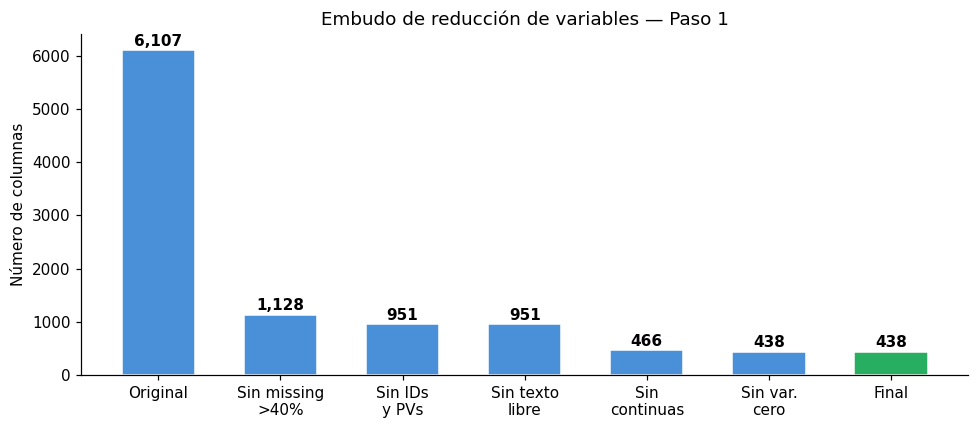

In [238]:
# Visualización del embudo de reducción
etapas = [
    "Original",
    "Sin missing\n>40%",
    "Sin IDs\ny PVs",
    "Sin texto\nlibre",
    "Sin\ncontinuas",
    "Sin var.\ncero",
    "Final",
]

# Reconstruir conteos acumulados
n0 = df_raw.shape[1]
n1 = n0 - len(cols_alta_missing)
n2 = n1 - len(cols_pisa_derivadas)
n3 = n2 - len(cols_texto)
n4 = n3 - len(cols_continuas)
n5 = n4 - len(cols_varianza_cero)
n6 = df.shape[1]

valores = [n0, n1, n2, n3, n4, n5, n6]
colores = ["#4A90D9"] * 6 + ["#27AE60"]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(etapas, valores, color=colores, edgecolor="white", width=0.6)
for bar, val in zip(bars, valores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f"{val:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylabel("Número de columnas")
ax.set_title("Embudo de reducción de variables — Paso 1")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 9. Guardar outputs

In [239]:
# Dataset filtrado — listo para EFA
df.to_csv(f"{RUTA_OUTPUT}/dataset_filtrado.csv", index=False)
print("Guardado: dataset_filtrado.csv")

# Plausible Values separados — referencia de rendimiento para IRT y LCA
df_pv.to_csv(f"{RUTA_OUTPUT}/plausible_values_referencia.csv", index=False)
print("Guardado: plausible_values_referencia.csv")

# Variables continuas separadas — por si las necesitas en análisis descriptivo
df_continuas.to_csv(f"{RUTA_OUTPUT}/variables_continuas_separadas.csv", index=False)
print("Guardado: variables_continuas_separadas.csv")

# Mapeo de recodificación de categóricas
import json
with open(f"{RUTA_OUTPUT}/mapeo_categoricos.json", "w", encoding="utf-8") as f:
    # Convertir keys a str para JSON
    mapeos_serializables = {
        col: {str(k): str(v) for k, v in mapa.items()}
        for col, mapa in mapeos_categoricos.items()
    }
    json.dump(mapeos_serializables, f, ensure_ascii=False, indent=2)
print("Guardado: mapeo_categoricos.json")

# Lista de columnas eliminadas en cada paso — útil para el artículo
log_filtrado = pd.DataFrame({
    "columna": (
        list(cols_alta_missing) +
        list(cols_pisa_derivadas) +
        list(cols_texto) +
        list(cols_continuas) +
        list(cols_varianza_cero)
    ),
    "razon_eliminacion": (
        ["missing >40%"]       * len(cols_alta_missing) +
        ["ID/peso/PV/derivada"] * len(cols_pisa_derivadas) +
        ["texto libre"]        * len(cols_texto) +
        ["continua"]           * len(cols_continuas) +
        ["varianza casi cero"] * len(cols_varianza_cero)
    )
})
log_filtrado.to_csv(f"{RUTA_OUTPUT}/log_columnas_eliminadas.csv", index=False)
print("Guardado: log_columnas_eliminadas.csv")

print(f"\n✓ Paso 1 completado. Dataset listo: {df.shape[0]:,} filas × {df.shape[1]:,} columnas")

Guardado: dataset_filtrado.csv
Guardado: plausible_values_referencia.csv
Guardado: variables_continuas_separadas.csv
Guardado: mapeo_categoricos.json
Guardado: log_columnas_eliminadas.csv

✓ Paso 1 completado. Dataset listo: 6,086 filas × 438 columnas


## 10. Vista previa del dataset final

In [240]:
print("Primeras columnas del dataset filtrado:")
print(df.columns[:20].tolist())
print()
df.head(3)

Primeras columnas del dataset filtrado:
['RDESIGN', 'RCORE_TEST', 'RS1_TEST', 'RS1_LEV', 'RS2_TEST', 'RS2_LEV', 'RCORE_PERF', 'RCO1S_PERF', 'ST001D01T', 'ST003D03T', 'ST004D01T', 'ST005Q01TA', 'ST006Q01TA', 'ST006Q02TA', 'ST006Q03TA', 'ST006Q04TA', 'ST007Q01TA', 'ST008Q01TA', 'ST008Q02TA', 'ST008Q03TA']



,RDESIGN,RCORE_TEST,RS1_TEST,RS1_LEV,RS2_TEST,RS2_LEV,RCORE_PERF,RCO1S_PERF,ST001D01T,ST003D03T,...,SC152Q01HA,SC052Q01NA,SC052Q02NA,SC052Q03HA,SCHLTYPE,CLSIZE,CREACTIV,TC186Q01HA,VER_DAT_stu_all,PRIVATESCH
0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,2002.0,...,2.0,1.0,2.0,2.0,3.0,28.0,1.0,1.0,0,0
1,2.0,5.0,11.0,1.0,22.0,2.0,2.0,2.0,10.0,2002.0,...,1.0,1.0,1.0,1.0,3.0,28.0,3.0,1.0,0,0
2,2.0,6.0,16.0,2.0,23.0,1.0,3.0,2.0,10.0,2003.0,...,1.0,2.0,2.0,1.0,1.0,23.0,3.0,1.0,1,1


In [241]:
# Distribución de missing en el dataset final
missing_final = df.isnull().mean()
print(f"Columnas sin ningún missing : {(missing_final == 0).sum()}")
print(f"Columnas con algo de missing: {(missing_final > 0).sum()}")
print(f"Missing promedio por columna: {missing_final.mean():.2%}")
print()
print("Siguiente paso → paso2_efa_por_bloques.ipynb")

Columnas sin ningún missing : 24
Columnas con algo de missing: 414
Missing promedio por columna: 7.39%

Siguiente paso → paso2_efa_por_bloques.ipynb


CAlculando missing real de variables que sobrevivieron al filtrado.

In [244]:
import pandas as pd
df = pd.read_csv("/workspace/data/output/2018/national/dataset_filtrado.csv")

missing = df.isnull().mean()
print("Distribución de missing en dataset filtrado:")
print(f"  Sin missing (0%)     : {(missing == 0).sum()} columnas")
print(f"  Missing leve (1-10%) : {((missing > 0) & (missing <= 0.10)).sum()} columnas")
print(f"  Missing medio(10-40%): {((missing > 0.10) & (missing <= 0.40)).sum()} columnas")
print(f"  Missing promedio     : {missing.mean():.2%}")

Distribución de missing en dataset filtrado:
  Sin missing (0%)     : 24 columnas
  Missing leve (1-10%) : 305 columnas
  Missing medio(10-40%): 109 columnas
  Missing promedio     : 7.39%
